# 1. EDA on Netflix Data
Goal: Understand content trends by year, genre, and country.

#
Import libraries and load data

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("netflix_titles.csv")

print(df.head())
print(df.info())
print(df.isnull().sum())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

# 
Movies vs TV Shows

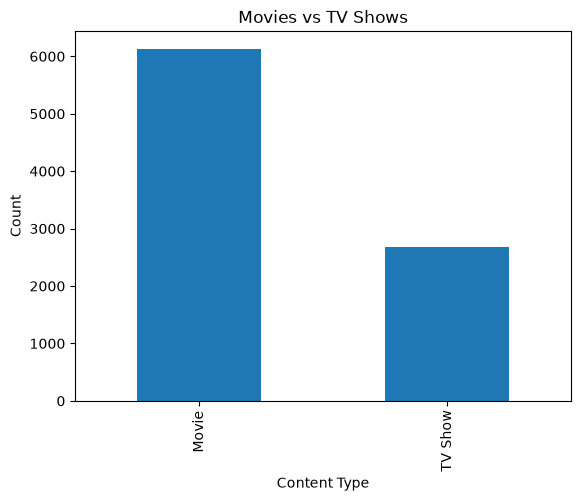

In [12]:

df["type"].value_counts().plot(kind="bar")
plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Count")
plt.show()

#
 Content added by year

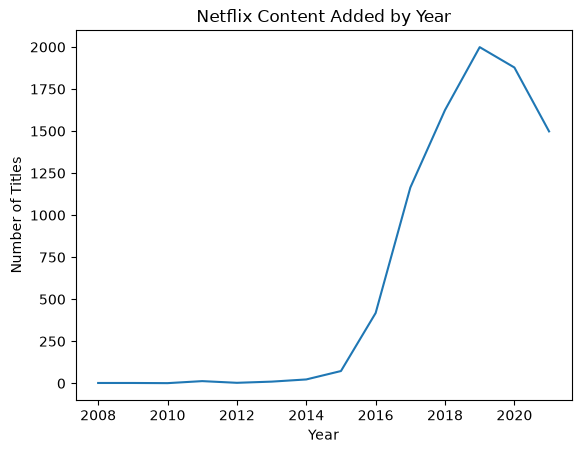

In [13]:

df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["year_added"] = df["date_added"].dt.year

df["year_added"].value_counts().sort_index().plot(kind="line")
plt.title("Netflix Content Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.show()

# 
Top 10 genres

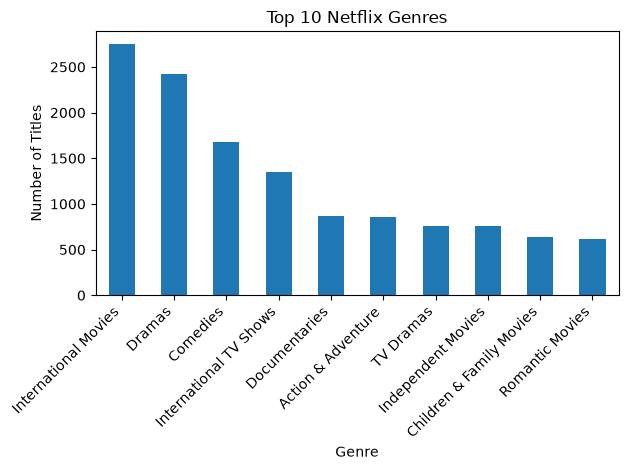

In [14]:

genres = df["listed_in"].dropna().str.split(", ").explode()
genres.value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Netflix Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 
Top 10 countries

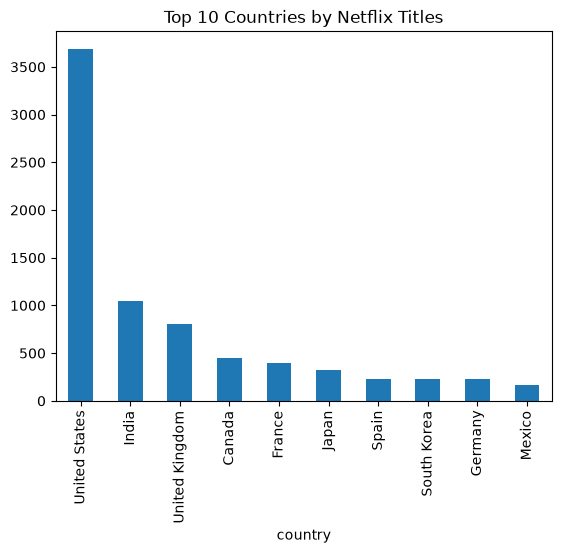

In [15]:
# Top 10 countries
countries = df["country"].dropna().str.split(", ").explode()
countries.value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Countries by Netflix Titles")
plt.show()

# 2. EDA on Sales Data
Goal: Analyze revenue patterns, customer behavior, and seasonality.

# 
Import libraries and load data

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sales_data.csv")

df["Sale_Date"] = pd.to_datetime(df["Sale_Date"])

print(df.head())
print(df.info())
print(df.isnull().sum())
print(df.describe())

   Product_ID  Sale_Date Sales_Rep Region  Sales_Amount  Quantity_Sold  \
0        1052 2023-02-03       Bob  North       5053.97             18   
1        1093 2023-04-21       Bob   West       4384.02             17   
2        1015 2023-09-21     David  South       4631.23             30   
3        1072 2023-08-24       Bob  South       2167.94             39   
4        1061 2023-03-24   Charlie   East       3750.20             13   

  Product_Category  Unit_Cost  Unit_Price Customer_Type  Discount  \
0        Furniture     152.75      267.22     Returning      0.09   
1        Furniture    3816.39     4209.44     Returning      0.11   
2             Food     261.56      371.40     Returning      0.20   
3         Clothing    4330.03     4467.75           New      0.02   
4      Electronics     637.37      692.71           New      0.08   

  Payment_Method Sales_Channel Region_and_Sales_Rep  
0           Cash        Online            North-Bob  
1           Cash        Retail  

# 
Calculate revenue

In [25]:
print("Total Revenue:", df["Sales_Amount"].sum())

print(df[["Product_ID", "Quantity_Sold", "Unit_Price", "Sales_Amount"]].head())

Total Revenue: 5019265.2299999995
   Product_ID  Quantity_Sold  Unit_Price  Sales_Amount
0        1052             18      267.22       5053.97
1        1093             17     4209.44       4384.02
2        1015             30      371.40       4631.23
3        1072             39     4467.75       2167.94
4        1061             13      692.71       3750.20


#
Bar chart — sales by region

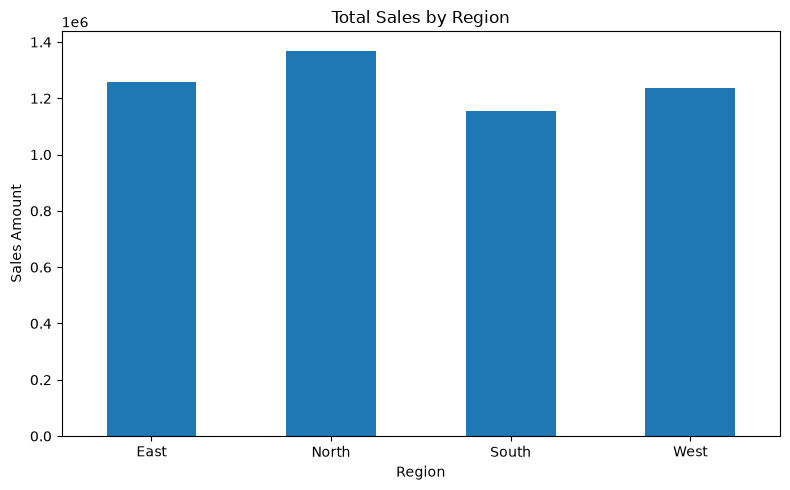

In [26]:
region_sales = df.groupby("Region")["Sales_Amount"].sum()

region_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Pie chart — product categories

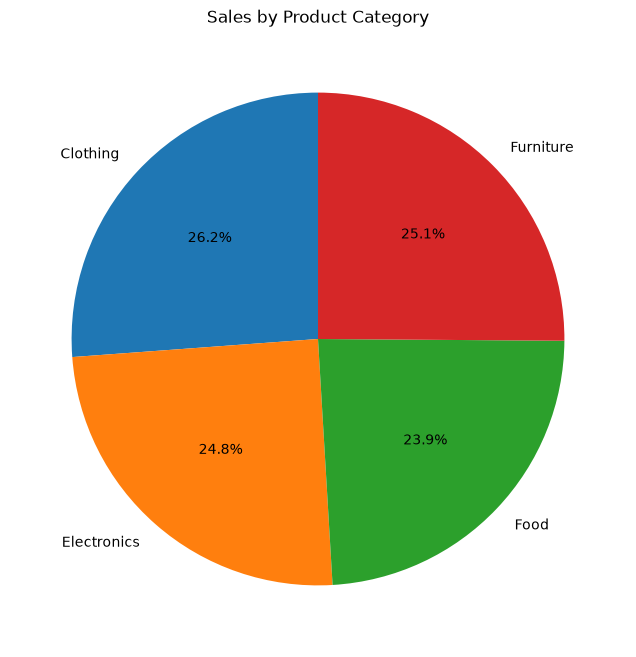

In [27]:
category_sales = df.groupby("Product_Category")["Sales_Amount"].sum()

plt.figure(figsize=(8, 8))
plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales by Product Category")
plt.show()

Line chart — monthly revenue trends

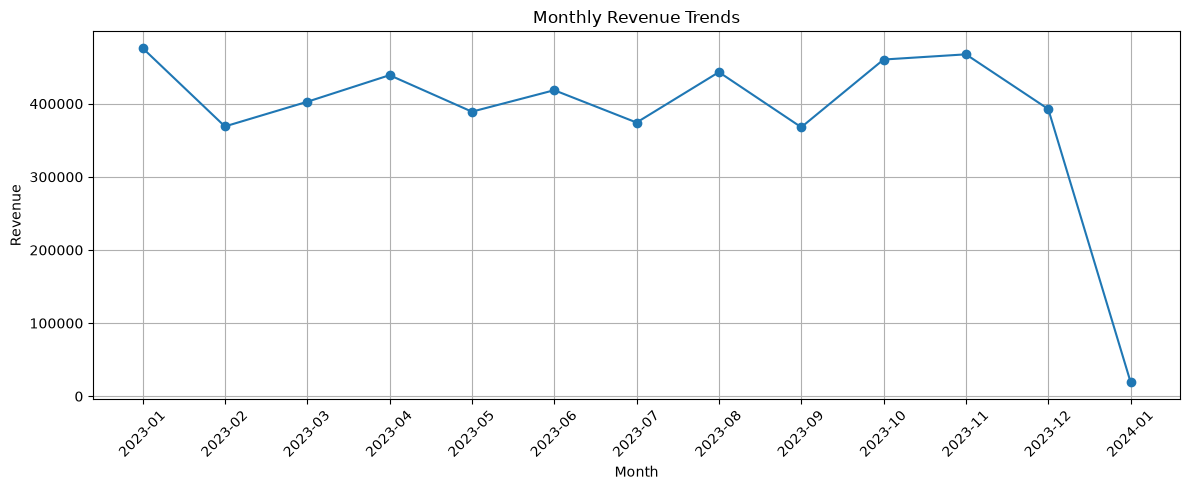

In [28]:
df["Month"] = df["Sale_Date"].dt.to_period("M")

monthly_revenue = df.groupby("Month")["Sales_Amount"].sum()

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trends")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Customer behavior analysis

Customer_Type
New          2506258.30
Returning    2513006.93
Name: Sales_Amount, dtype: float64


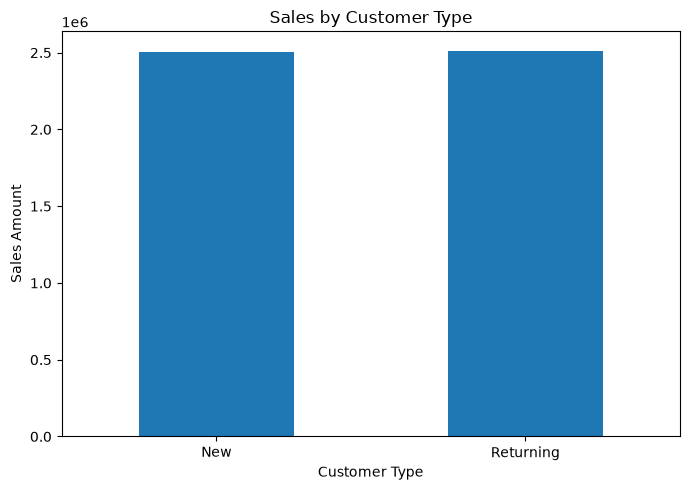

In [29]:
customer_sales = df.groupby("Customer_Type")["Sales_Amount"].sum()

print(customer_sales)

customer_sales.plot(kind="bar", figsize=(7, 5))
plt.title("Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Analyze sales channels

Sales_Channel
Online    2458833.93
Retail    2560431.30
Name: Sales_Amount, dtype: float64


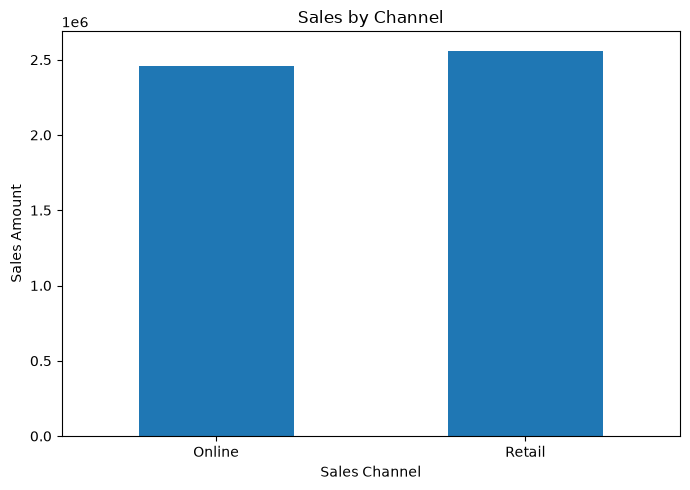

In [30]:
channel_sales = df.groupby("Sales_Channel")["Sales_Amount"].sum()

print(channel_sales)

channel_sales.plot(kind="bar", figsize=(7, 5))
plt.title("Sales by Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Analyze product quantity

Product_Category
Clothing       6922
Furniture      6729
Electronics    6096
Food           5608
Name: Quantity_Sold, dtype: int64


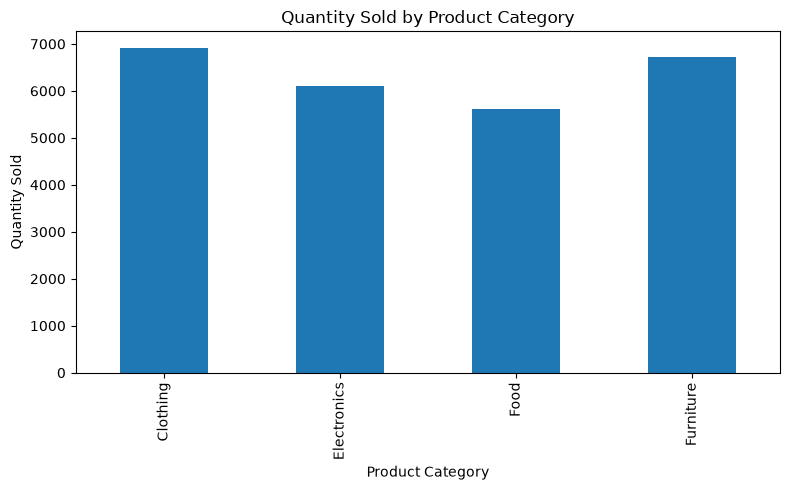

In [31]:
product_quantity = df.groupby("Product_Category")["Quantity_Sold"].sum()

print(product_quantity.sort_values(ascending=False))

product_quantity.plot(kind="bar", figsize=(8, 5))
plt.title("Quantity Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Quantity Sold")
plt.tight_layout()
plt.show()

Final insights

In [32]:
print("Total Sales:", df["Sales_Amount"].sum())
print("Average Sale:", df["Sales_Amount"].mean())

print("Best Region:")
print(df.groupby("Region")["Sales_Amount"].sum().idxmax())

print("Best Product Category:")
print(df.groupby("Product_Category")["Sales_Amount"].sum().idxmax())

print("Best Sales Channel:")
print(df.groupby("Sales_Channel")["Sales_Amount"].sum().idxmax())

Total Sales: 5019265.2299999995
Average Sale: 5019.265229999999
Best Region:
North
Best Product Category:
Clothing
Best Sales Channel:
Retail


# 3. EDA on COVID-19 Data
Goal: Explore spread patterns, recovery rates, and trends over time.

# 
Load dataset

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("countries-aggregated.csv")


print(df.head())


print(df.columns)

print(df.isnull().sum())

         Date      Country  Confirmed  Recovered  Deaths
0  2020-01-22  Afghanistan          0          0       0
1  2020-01-23  Afghanistan          0          0       0
2  2020-01-24  Afghanistan          0          0       0
3  2020-01-25  Afghanistan          0          0       0
4  2020-01-26  Afghanistan          0          0       0
Index(['Date', 'Country', 'Confirmed', 'Recovered', 'Deaths'], dtype='str')
Date         0
Country      0
Confirmed    0
Recovered    0
Deaths       0
dtype: int64


# 
Filter COVID-19 data for India

In [48]:

country = df[df["Country"] == "India"].copy()

# Convert date column
country["Date"] = pd.to_datetime(country["Date"])

# Sort by date
country = country.sort_values("Date")

print(country.head())
print(country.tail())

            Date Country  Confirmed  Recovered  Deaths
65280 2020-01-22   India          0          0       0
65281 2020-01-23   India          0          0       0
65282 2020-01-24   India          0          0       0
65283 2020-01-25   India          0          0       0
65284 2020-01-26   India          0          0       0
            Date Country  Confirmed  Recovered  Deaths
66091 2022-04-12   India   43038016          0  521736
66092 2022-04-13   India   43039023          0  521737
66093 2022-04-14   India   43039972          0  521743
66094 2022-04-15   India   43040947          0  521747
66095 2022-04-16   India   43042097          0  521751


# 
Daily new cases

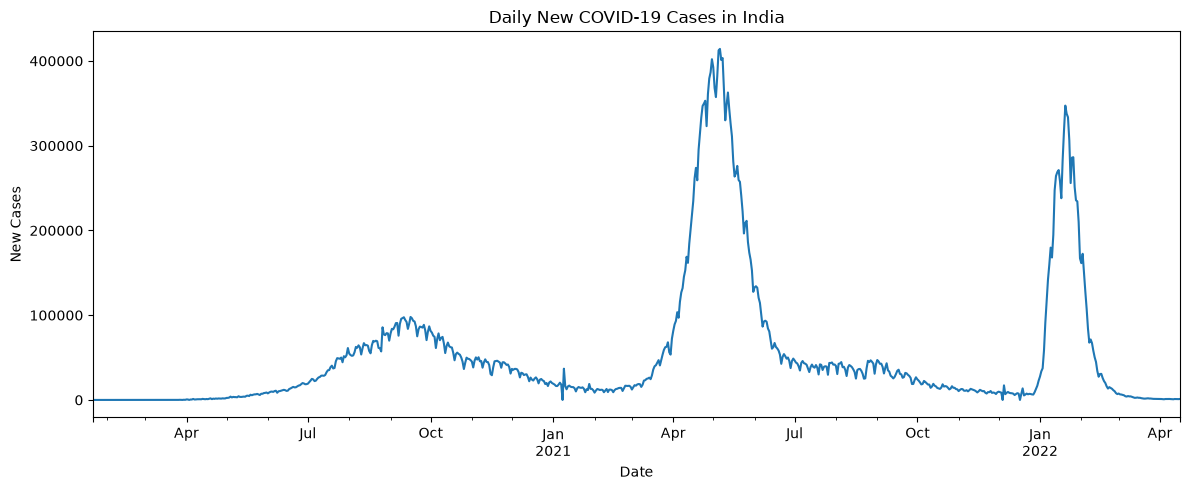

In [49]:

country["New_Cases"] = country["Confirmed"].diff().fillna(
    country["Confirmed"]
)

# Avoid negative values caused by reporting corrections
country["New_Cases"] = country["New_Cases"].clip(lower=0)

country.plot(
    x="Date",
    y="New_Cases",
    figsize=(12, 5),
    title="Daily New COVID-19 Cases in India",
    legend=False
)

plt.xlabel("Date")
plt.ylabel("New Cases")
plt.tight_layout()
plt.show()

# 
Cumulative confirmed cases

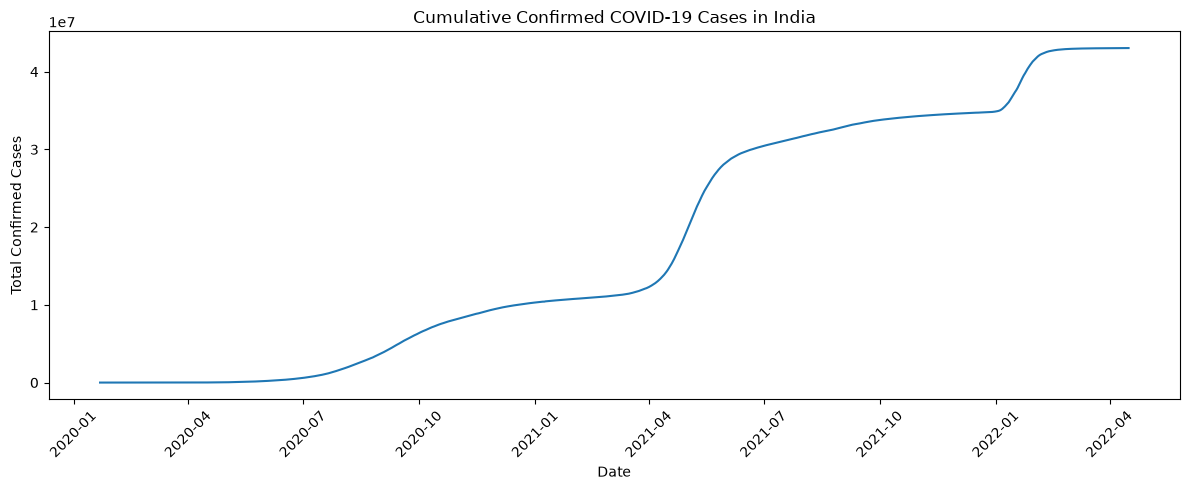

In [50]:
plt.figure(figsize=(12, 5))

plt.plot(country["Date"], country["Confirmed"])

plt.title("Cumulative Confirmed COVID-19 Cases in India")
plt.xlabel("Date")
plt.ylabel("Total Confirmed Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 
Total deaths

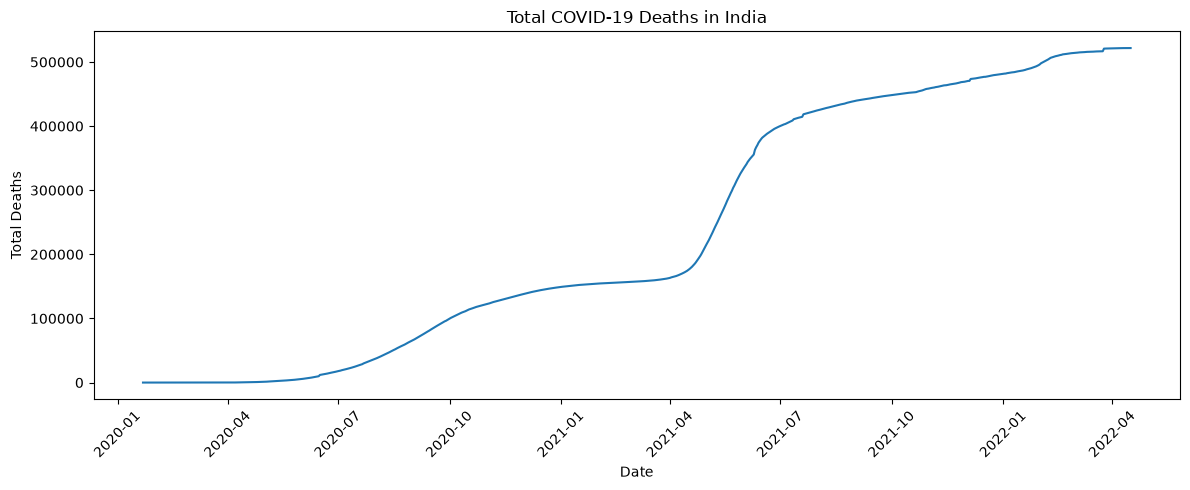

In [51]:

plt.figure(figsize=(12, 5))

plt.plot(country["Date"], country["Deaths"])

plt.title("Total COVID-19 Deaths in India")
plt.xlabel("Date")
plt.ylabel("Total Deaths")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 
Total recoveries

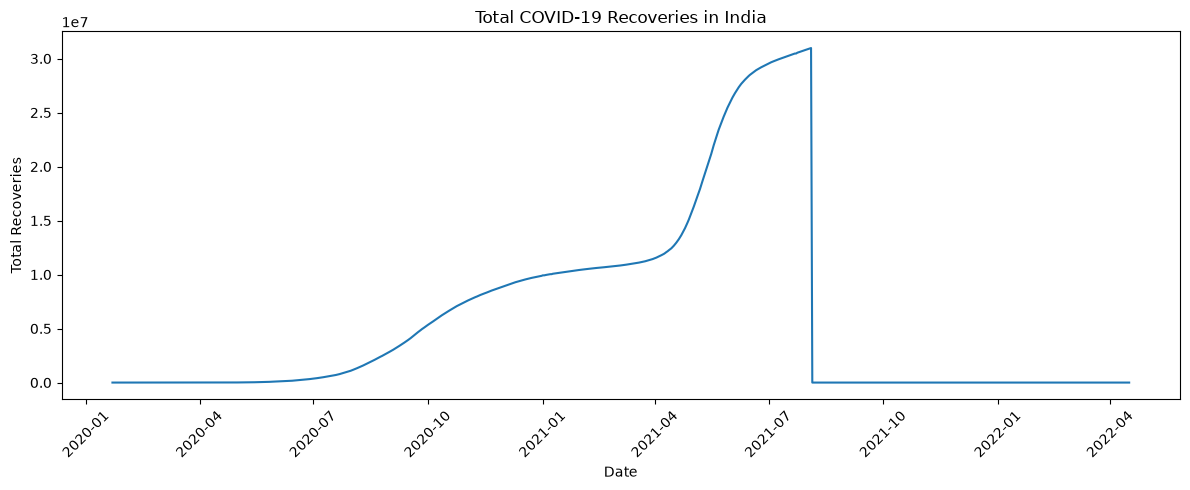

In [52]:

plt.figure(figsize=(12, 5))

plt.plot(country["Date"], country["Recovered"])

plt.title("Total COVID-19 Recoveries in India")
plt.xlabel("Date")
plt.ylabel("Total Recoveries")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Recovery rate

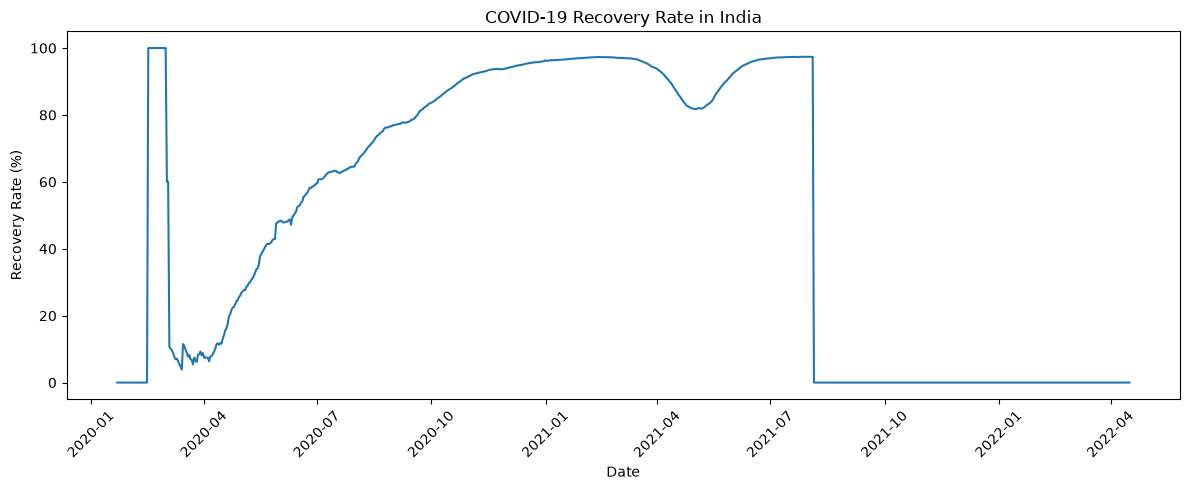

In [53]:
country["Recovery_Rate"] = (
    country["Recovered"] / country["Confirmed"] * 100
).fillna(0)

plt.figure(figsize=(12, 5))

plt.plot(country["Date"], country["Recovery_Rate"])

plt.title("COVID-19 Recovery Rate in India")
plt.xlabel("Date")
plt.ylabel("Recovery Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Daily new deaths

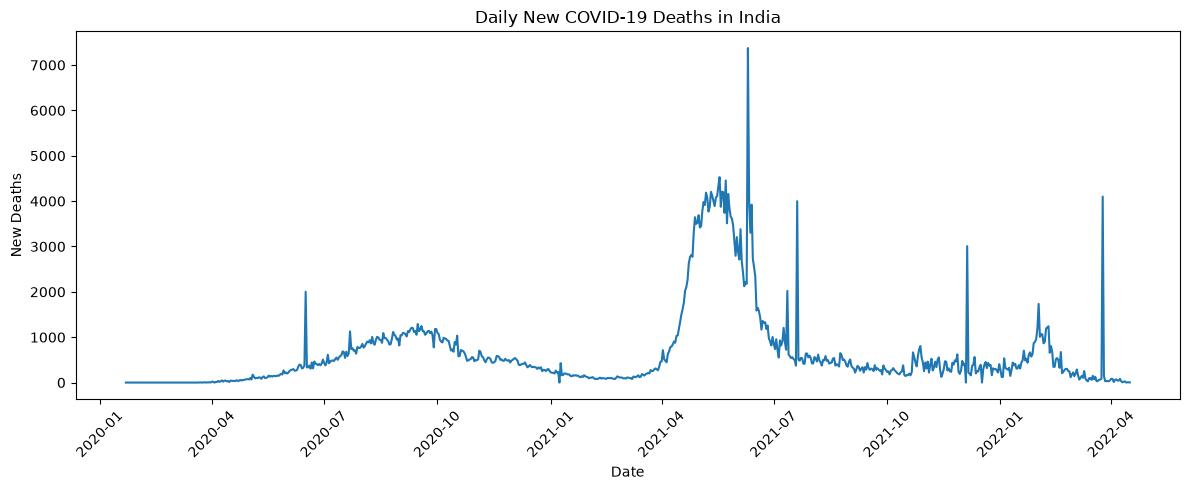

In [54]:
country["New_Deaths"] = country["Deaths"].diff().fillna(
    country["Deaths"]
)

country["New_Deaths"] = country["New_Deaths"].clip(lower=0)

plt.figure(figsize=(12, 5))

plt.plot(country["Date"], country["New_Deaths"])

plt.title("Daily New COVID-19 Deaths in India")
plt.xlabel("Date")
plt.ylabel("New Deaths")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Monthly COVID-19 trends

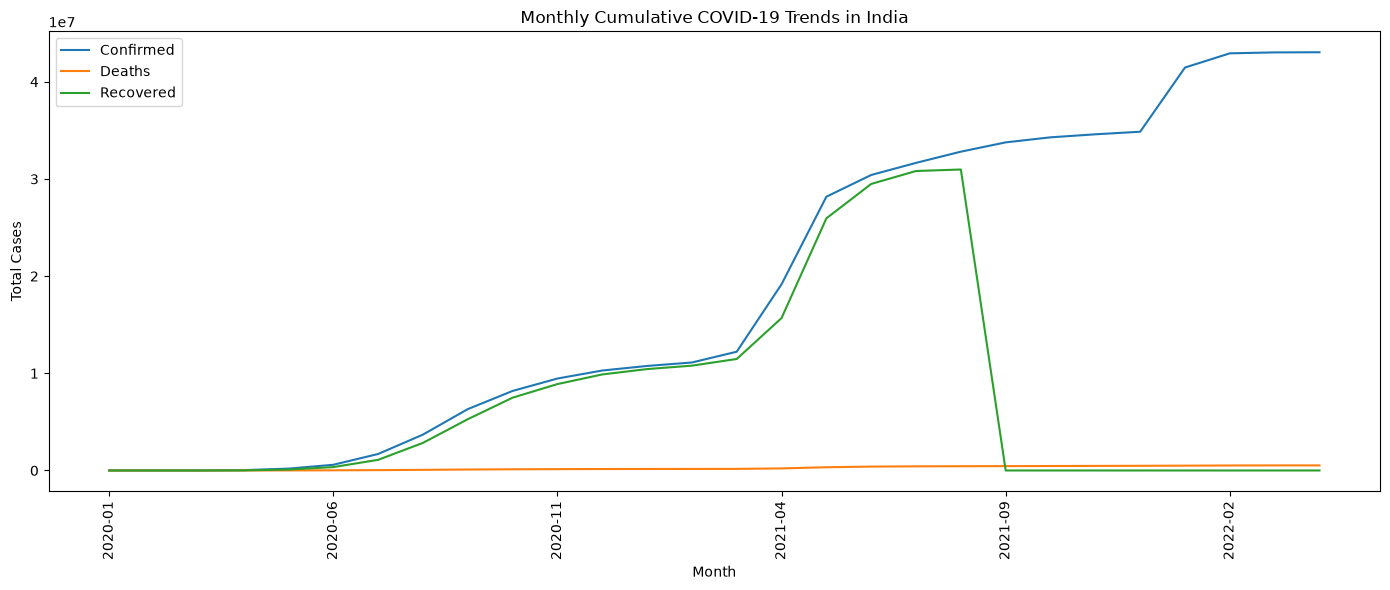

In [55]:
country["Month"] = country["Date"].dt.to_period("M")

monthly = country.groupby("Month").agg({
    "Confirmed": "max",
    "Deaths": "max",
    "Recovered": "max"
})

monthly.index = monthly.index.astype(str)

monthly[["Confirmed", "Deaths", "Recovered"]].plot(
    figsize=(14, 6),
    title="Monthly Cumulative COVID-19 Trends in India"
)

plt.xlabel("Month")
plt.ylabel("Total Cases")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Summary statistics

In [56]:
print("COVID-19 Analysis Summary for India")

print("Total Confirmed Cases:", country["Confirmed"].max())
print("Total Deaths:", country["Deaths"].max())
print("Total Recoveries:", country["Recovered"].max())

print(
    "Overall Recovery Rate:",
    round(country["Recovery_Rate"].iloc[-1], 2), "%"
)

print(
    "Highest Daily New Cases:",
    int(country["New_Cases"].max())
)

print(
    "Date of Highest Daily New Cases:",
    country.loc[country["New_Cases"].idxmax(), "Date"].date()
)

COVID-19 Analysis Summary for India
Total Confirmed Cases: 43042097
Total Deaths: 521751
Total Recoveries: 30974748
Overall Recovery Rate: 0.0 %
Highest Daily New Cases: 414188
Date of Highest Daily New Cases: 2021-05-06
